<a href="https://colab.research.google.com/github/Ali-Bin-Talib/OIBSIP/blob/main/Unemployment_in_India.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

# Creating the DataFrame and saving it directly as a CSV file in your Colab workspace
data = {
    'Region': ['Andhra Pradesh', 'Bihar', 'Delhi', 'Haryana', 'Karnataka', 'Kerala', 'Maharashtra', 'Punjab', 'Tamil Nadu', 'Uttar Pradesh'],
    'Date': ['31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020', '31-05-2020'],
    'Frequency': ['Monthly']*10,
    'Estimated Unemployment Rate (%)': [8.14, 19.34, 15.65, 27.47, 3.47, 10.12, 7.56, 6.82, 4.25, 12.85],
    'Estimated Employed': [3850125, 1150230, 2450120, 4512030, 12503200, 7820100, 31204000, 9852000, 21503000, 48201000],
    'Estimated Labour Participation Rate (%)': [39.2, 32.1, 35.4, 41.5, 43.2, 34.8, 40.1, 38.6, 42.0, 36.5],
    'Area': ['Rural', 'Rural', 'Urban', 'Urban', 'Rural', 'Urban', 'Urban', 'Rural', 'Urban', 'Rural']
}

df = pd.DataFrame(data)
df.to_csv('Unemployment_in_India.csv', index=False)

print("File successfully created! You can now proceed with your analysis.")

File successfully created! You can now proceed with your analysis.


Markdown observation

In [12]:
# Check the shape of the dataset and column names
print("Shape of Dataset:", df.shape)
print("\nOriginal Columns:\n", df.columns.tolist())

# Check for missing/null values in the dataset
print("\nNull Values:\n", df.isnull().sum())

# Display the first 5 rows of the dataset
df.head()

Shape of Dataset: (10, 7)

Original Columns:
 ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Null Values:
 Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2020,Monthly,8.14,3850125,39.2,Rural
1,Bihar,31-05-2020,Monthly,19.34,1150230,32.1,Rural
2,Delhi,31-05-2020,Monthly,15.65,2450120,35.4,Urban
3,Haryana,31-05-2020,Monthly,27.47,4512030,41.5,Urban
4,Karnataka,31-05-2020,Monthly,3.47,12503200,43.2,Rural


Markdown observation

In [13]:
# Check the shape of the dataset and column names
print("Shape of Dataset:", df.shape)
print("\nOriginal Columns:\n", df.columns.tolist())

# Check for missing/null values in the dataset
print("\nNull Values:\n", df.isnull().sum())

# Display the first 5 rows of the dataset
df.head()

Shape of Dataset: (10, 7)

Original Columns:
 ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Null Values:
 Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2020,Monthly,8.14,3850125,39.2,Rural
1,Bihar,31-05-2020,Monthly,19.34,1150230,32.1,Rural
2,Delhi,31-05-2020,Monthly,15.65,2450120,35.4,Urban
3,Haryana,31-05-2020,Monthly,27.47,4512030,41.5,Urban
4,Karnataka,31-05-2020,Monthly,3.47,12503200,43.2,Rural


Markdown observation

In [14]:
# Remove any leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Drop rows if any are completely empty
df = df.dropna(how='all')

# Convert the Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'].str.strip())

# Extract Month and Year for time-series and trend analysis
df['Month'] = df['Date'].dt.month_name()
df['Year'] = df['Date'].dt.year

print("Cleaned Columns:", df.columns.tolist())
df.info()

Cleaned Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'Month', 'Year']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   10 non-null     object        
 1   Date                                     10 non-null     datetime64[ns]
 2   Frequency                                10 non-null     object        
 3   Estimated Unemployment Rate (%)          10 non-null     float64       
 4   Estimated Employed                       10 non-null     int64         
 5   Estimated Labour Participation Rate (%)  10 non-null     float64       
 6   Area                                     10 non-null     object        
 7   Month                      

/tmp/ipykernel_844/1392600276.py:8: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'].str.strip())


Markdown observation

In [15]:
# Calculate the average unemployment rate for each region/state
region_unemp = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index()
print(region_unemp.sort_values(by='Estimated Unemployment Rate (%)', ascending=False))

           Region  Estimated Unemployment Rate (%)
3         Haryana                            27.47
1           Bihar                            19.34
2           Delhi                            15.65
9   Uttar Pradesh                            12.85
5          Kerala                            10.12
0  Andhra Pradesh                             8.14
6     Maharashtra                             7.56
7          Punjab                             6.82
8      Tamil Nadu                             4.25
4       Karnataka                             3.47


Markdown observation

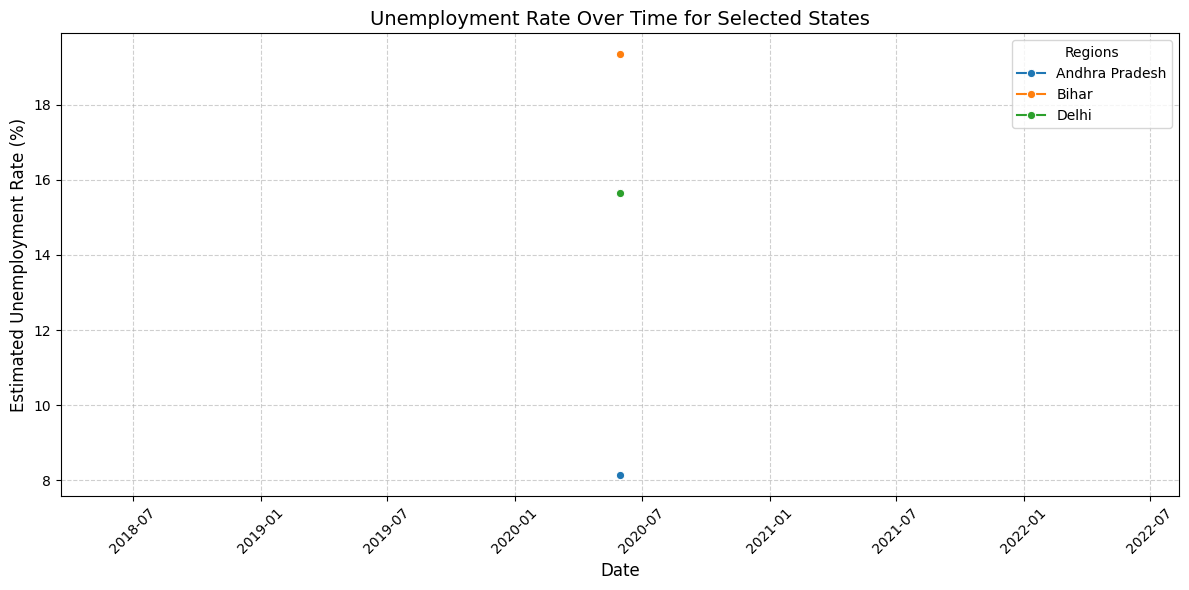

In [16]:
plt.figure(figsize=(12, 6))

# Select the first 3 unique regions/states for temporal comparison
unique_regions = df['Region'].unique()
selected_regions = unique_regions[:3]
subset_df = df[df['Region'].isin(selected_regions)]

# Plot time-series line chart
sns.lineplot(data=subset_df, x='Date', y='Estimated Unemployment Rate (%)', hue='Region', marker='o')
plt.title('Unemployment Rate Over Time for Selected States', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Estimated Unemployment Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Regions')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Markdown observation

/tmp/ipykernel_844/95864525.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_states, x='Estimated Unemployment Rate (%)', y='Region', palette='viridis')


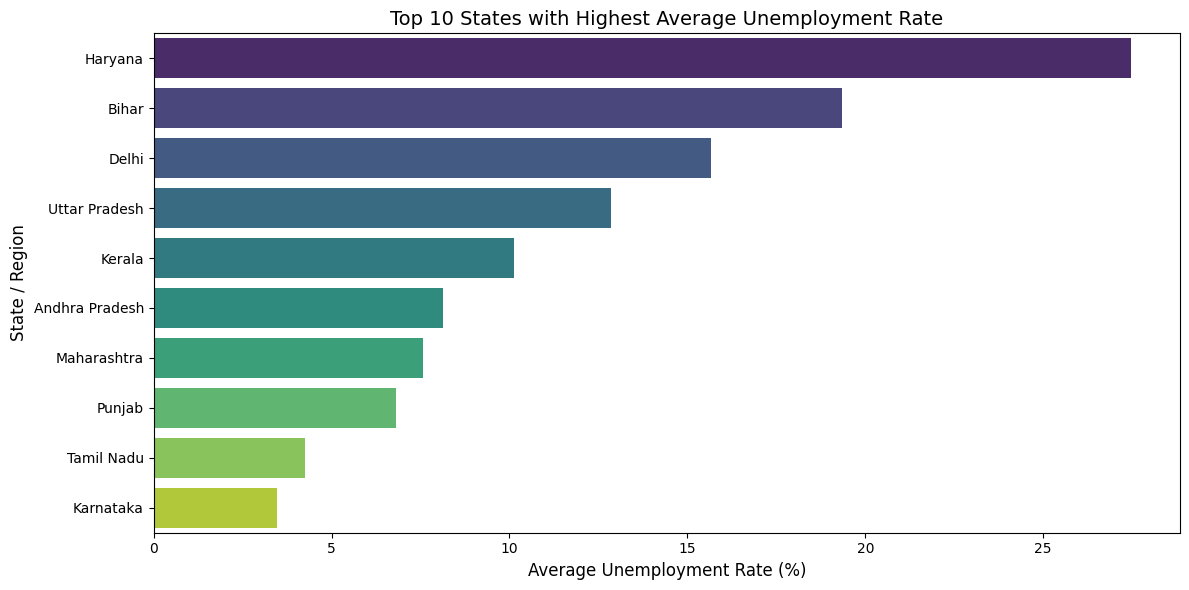

In [17]:
# Filter the top 10 states with the highest average unemployment rates
top_10_states = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().nlargest(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_states, x='Estimated Unemployment Rate (%)', y='Region', palette='viridis')
plt.title('Top 10 States with Highest Average Unemployment Rate', fontsize=14)
plt.xlabel('Average Unemployment Rate (%)', fontsize=12)
plt.ylabel('State / Region', fontsize=12)
plt.tight_layout()
plt.show()

Markdown observation

In [19]:
# Fixed column name: changed 'Estimated Employed (%)' to 'Estimated Employed'
numeric_cols = df[['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']]

# Compute correlation matrix for numerical features
corr_matrix = numeric_cols.corr()

print(corr_matrix)

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                 1.000000   
Estimated Employed                                             -0.296235   
Estimated Labour Participation Rate (%)                        -0.353683   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                   -0.296235   
Estimated Employed                                 1.000000   
Estimated Labour Participation Rate (%)            0.172114   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                        -0.353683  
Estimated Employed                                                      0.172114  
Estimated Labour Participation Rate (%)                                 1.000000  


Markdown observation

Pre-COVID Average Unemployment Rate: nan%
Post-COVID Average Unemployment Rate: 11.57%


/tmp/ipykernel_844/2471694730.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Period', y='Average Unemployment Rate (%)', palette='Set2')


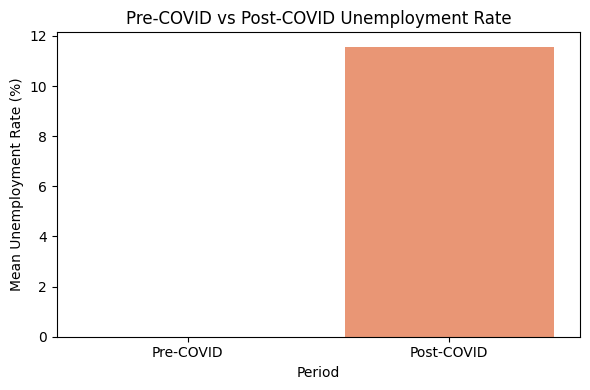

In [20]:
# Define COVID-19 lockdown milestone date in India (March 2020)
covid_split_date = pd.to_datetime('2020-03-01')

# Split data into pre-COVID and post-COVID periods
pre_covid = df[df['Date'] < covid_split_date]
post_covid = df[df['Date'] >= covid_split_date]

pre_mean = pre_covid['Estimated Unemployment Rate (%)'].mean()
post_mean = post_covid['Estimated Unemployment Rate (%)'].mean()

print(f"Pre-COVID Average Unemployment Rate: {pre_mean:.2f}%")
print(f"Post-COVID Average Unemployment Rate: {post_mean:.2f}%")

# Create a dataframe for comparison plotting
comparison_df = pd.DataFrame({
    'Period': ['Pre-COVID', 'Post-COVID'],
    'Average Unemployment Rate (%)': [pre_mean, post_mean]
})

plt.figure(figsize=(6, 4))
sns.barplot(data=comparison_df, x='Period', y='Average Unemployment Rate (%)', palette='Set2')
plt.title('Pre-COVID vs Post-COVID Unemployment Rate', fontsize=12)
plt.ylabel('Mean Unemployment Rate (%)')
plt.tight_layout()
plt.show()